In [1]:
!pip install pingouin factor_analyzer -q

In [2]:
!pip install --upgrade numpy scipy pingouin factor_analyzer

In [3]:
import pandas as pd, numpy as np, pingouin as pg
from scipy import stats
from factor_analyzer import FactorAnalyzer, calculate_kmo, calculate_bartlett_sphericity

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [4]:
from google.colab import files
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses 3 TIC).xlsx to Blank Quiz (Responses 3 TIC).xlsx
File terbaca: Blank Quiz (Responses 3 TIC).xlsx


In [6]:
JUMLAH_KOLOM_DEMOGRAFI = 5
df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]
print("Jumlah responden :", len(df))
print("Jumlah butir :", butir.shape[1])
print("Data kosong :", int(butir.isna().sum().sum()))

Jumlah responden : 40
Jumlah butir : 30
Data kosong : 0


In [11]:
# 1. Bersihkan spasi berlebih di awal/akhir teks jika ada
butir_clean = butir.apply(
    lambda col: col.str.strip() if col.dtype == "object" else col
)

# 2. Definisikan skala konversi
skala = {
    "Sangat Tidak Setuju (STJ)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

# 3. Jalankan konversi ke angka
num = butir_clean.replace(skala).apply(pd.to_numeric, errors="coerce")

# 4. Cek apakah masih ada sel yang gagal
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 40


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Respon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Respon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Respon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Respon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Respon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,5,5,4,4,4,4,4,5,4,4,...,2,5,4,5,4,5,5,4,4,5
1,4,4,4,4,4,4,4,5,4,4,...,4,2,4,4,4,5,4,5,5,5
2,5,5,4,4,4,4,4,4,4,4,...,2,4,5,4,2,5,5,5,4,5
3,5,4,5,2,4,5,5,4,4,2,...,2,4,4,4,4,5,4,4,4,4
4,5,5,4,4,5,5,5,4,2,4,...,2,2,2,2,4,5,5,4,5,5


In [12]:
import re

dimensi = {}
for kolom in butir.columns:
    match = re.match(r"^(.*?) \[", kolom)
    if match:
        nama = match.group(1)
        dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah : 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
 Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik.: 4 butir
Respon emosional: 5 butir


In [13]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 40 | r tabel (α=0,05; df=38) = 0.312


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.419,0.222,0.0071,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.390,0.224,0.0129,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.626,0.418,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.506,0.205,0.0009,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.793,0.597,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.634,0.424,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.231,-0.061,0.1510,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.578,0.437,0.0001,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.708,0.541,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.804,0.651,0.0000,Valid


In [14]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))


def kategori(a):
    return (
        "Sangat baik"
        if a >= 0.90
        else "Baik" if a >= 0.80 else "Reliabel" if a >= 0.70 else "Tidak reliabel"
    )


hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })

    if len(daftar) > 2:
        for i, kolom in enumerate(daftar, 1):
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(
                    cronbach_alpha(x.drop(columns=kolom)), 3
                ),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)

display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.550,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.678,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.808,Baik
3,Prokrastinasi akademik.,4,0.865,Baik
4,Respon emosional,5,0.555,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.531
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.533
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.456
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.547
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.341
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.453
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.639
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.637
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.597
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.550


In [15]:
gabung = tabel_validitas.merge(
    tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left"
)

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

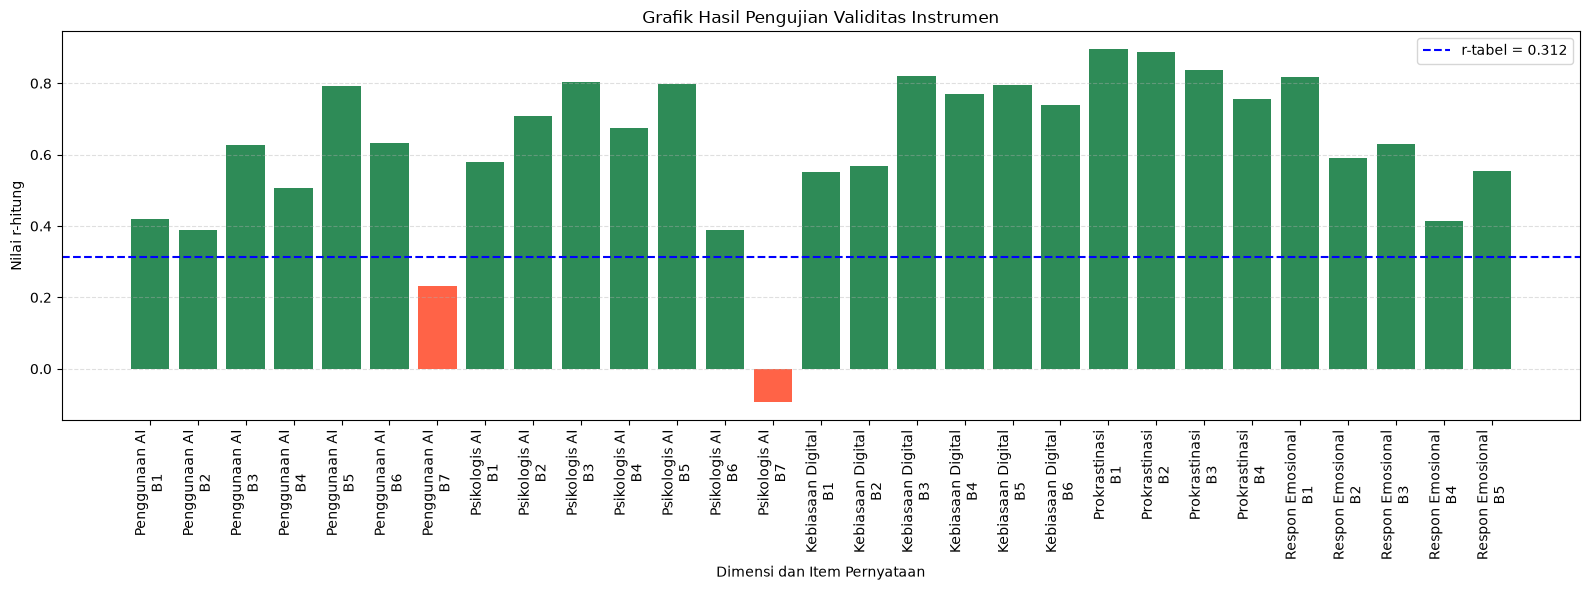

Jumlah Item Valid: 27
Jumlah Item Tidak Valid: 2


In [20]:

import matplotlib.pyplot as plt
import pandas as pd

# Data hasil pengujian validitas (40 responden)
data_validitas = {
    "Dimensi": [
        "Penggunaan AI"] * 7 +
        ["Psikologis AI"] * 7 +
        ["Kebiasaan Digital"] * 6 +
        ["Prokrastinasi"] * 4 +
        ["Respon Emosional"] * 5,

    "Item": (
        [f"B{i}" for i in range(1, 8)] +
        [f"B{i}" for i in range(1, 8)] +
        [f"B{i}" for i in range(1, 7)] +
        [f"B{i}" for i in range(1, 5)] +
        [f"B{i}" for i in range(1, 6)]
    ),

    "r_hitung": [
        0.419, 0.390, 0.626, 0.506, 0.793, 0.634, 0.231,
        0.578, 0.708, 0.804, 0.675, 0.797, 0.389, -0.094,
        0.551, 0.567, 0.819, 0.771, 0.796, 0.740,
        0.896, 0.888, 0.837, 0.757,
        0.817, 0.590, 0.631, 0.413, 0.553
    ]
}

df_validitas = pd.DataFrame(data_validitas)

# Nilai r-tabel untuk n=40
r_tabel = 0.312

# Menentukan status validitas
df_validitas["Status"] = df_validitas["r_hitung"].apply(
    lambda x: "Valid" if x > r_tabel else "Tidak Valid"
)

# Membuat label item agar tidak berulang
df_validitas["Label"] = (
    df_validitas["Dimensi"] + "\n" + df_validitas["Item"]
)

# Warna berdasarkan status
warna = [
    "seagreen" if x > r_tabel else "tomato"
    for x in df_validitas["r_hitung"]
]

# Membuat grafik
plt.figure(figsize=(16, 6))

plt.bar(
    df_validitas["Label"],
    df_validitas["r_hitung"],
    color=warna
)

plt.axhline(
    y=r_tabel,
    color="blue",
    linestyle="--",
    label=f"r-tabel = {r_tabel}"
)

plt.title("Grafik Hasil Pengujian Validitas Instrumen")
plt.xlabel("Dimensi dan Item Pernyataan")
plt.ylabel("Nilai r-hitung")
plt.xticks(rotation=90)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Menampilkan jumlah item valid dan tidak valid
print("Jumlah Item Valid:",
      (df_validitas["Status"] == "Valid").sum())

print("Jumlah Item Tidak Valid:",
      (df_validitas["Status"] == "Tidak Valid").sum())


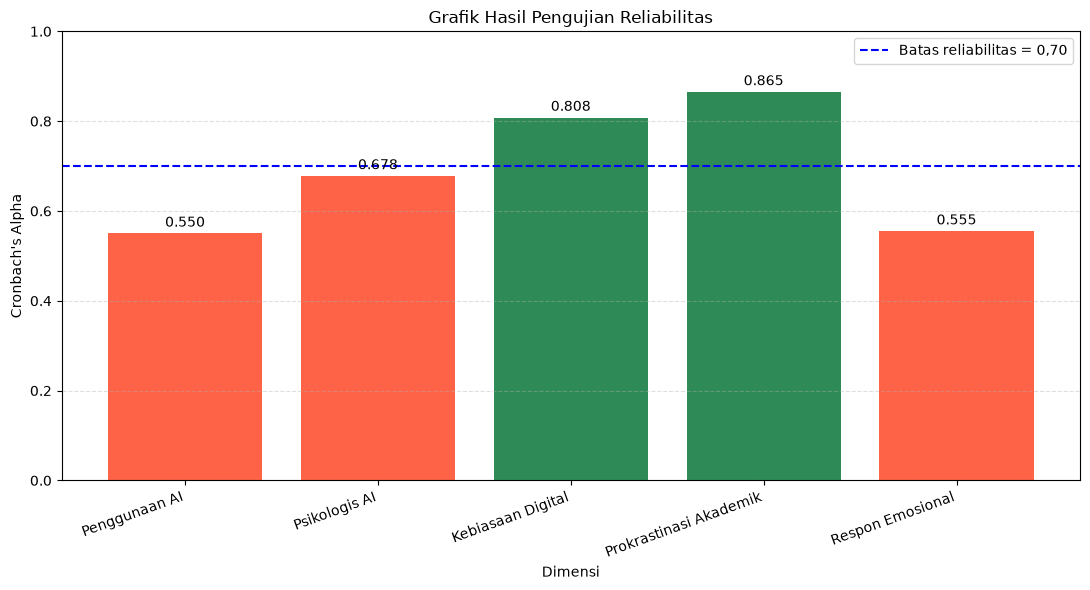

,Dimensi,Cronbach Alpha,Status
0,Penggunaan AI,0.550,Tidak Reliabel
1,Psikologis AI,0.678,Tidak Reliabel
2,Kebiasaan Digital,0.808,Reliabel
3,Prokrastinasi Akademik,0.865,Reliabel
4,Respon Emosional,0.555,Tidak Reliabel


In [21]:

import matplotlib.pyplot as plt
import pandas as pd

# Data hasil pengujian reliabilitas
data_reliabilitas = {
    "Dimensi": [
        "Penggunaan AI",
        "Psikologis AI",
        "Kebiasaan Digital",
        "Prokrastinasi Akademik",
        "Respon Emosional"
    ],

    "Cronbach Alpha": [
        0.550,
        0.678,
        0.808,
        0.865,
        0.555
    ]
}

df_reliabilitas = pd.DataFrame(data_reliabilitas)

# Batas minimal reliabilitas
batas_alpha = 0.70

# Menentukan status
df_reliabilitas["Status"] = df_reliabilitas[
    "Cronbach Alpha"
].apply(
    lambda x: "Reliabel" if x >= batas_alpha
    else "Tidak Reliabel"
)

# Warna berdasarkan status
warna = [
    "seagreen" if x >= batas_alpha else "tomato"
    for x in df_reliabilitas["Cronbach Alpha"]
]

# Membuat grafik
plt.figure(figsize=(11, 6))

bars = plt.bar(
    df_reliabilitas["Dimensi"],
    df_reliabilitas["Cronbach Alpha"],
    color=warna
)

# Garis batas reliabilitas
plt.axhline(
    y=batas_alpha,
    color="blue",
    linestyle="--",
    label="Batas reliabilitas = 0,70"
)

# Menampilkan angka pada setiap batang
for bar in bars:
    tinggi = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        tinggi + 0.015,
        f"{tinggi:.3f}",
        ha="center"
    )

plt.title("Grafik Hasil Pengujian Reliabilitas")
plt.xlabel("Dimensi")
plt.ylabel("Cronbach's Alpha")
plt.ylim(0, 1.0)
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Menampilkan hasil status reliabilitas
display(df_reliabilitas)
